<a href="https://colab.research.google.com/github/pedro-h-barbosa/bike-sharing-ffcd-ufpr/blob/main/P%C3%B3s_Gradua%C3%A7%C3%A3o_Bike.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# 1. Atualizar gerenciador de pacotes e instalar as bibliotecas necessárias para o projeto
!pip install --quiet --upgrade pip
!pip install --quiet "scikit-learn>=1.3.0" "lightgbm>=4.0.0" "shap>=0.42.0"

# 2. Testar e confirmar a importação e versões das ferramentas
import sys
import numpy as np
import pandas as pd
import sklearn
import lightgbm as lgb
import shap
import matplotlib
import seaborn as sns

print("=== AMBIENTE CONFIGURADO COM SUCESSO ===")
print(f"Versão do Python: {sys.version.split()[0]}")
print(f"Pandas: {pd.__version__}")
print(f"NumPy: {np.__version__}")
print(f"Scikit-Learn: {sklearn.__version__}")
print(f"LightGBM: {lgb.__version__}")
print(f"SHAP: {shap.__version__}")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.8/1.8 MB 24.9 MB/s eta 0:00:00
=== AMBIENTE CONFIGURADO COM SUCESSO ===
Versão do Python: 3.13.16
Pandas: 2.2.3
NumPy: 2.1.3
Scikit-Learn: 1.6.1
LightGBM: 4.6.0
SHAP: 0.52.0


In [ ]:
# ==============================================================================
# PASSO 2: CARREGAMENTO DOS DADOS E DIAGNÓSTICO EXPLORATÓRIO INICIAL (EXPLORE)
# ==============================================================================
import pandas as pd
import numpy as np

# 1. Download do arquivo ZIP oficial e descompactação seletiva do hour.csv
!wget -q https://archive.ics.uci.edu/static/public/275/bike+sharing+dataset.zip -O bike_dataset.zip
!unzip -q -o bike_dataset.zip hour.csv

# 2. Leitura da base de dados horária
df_raw = pd.read_csv('hour.csv')

print("--> Base horária carregada com sucesso!")
print(f"Dimensão da base: {df_raw.shape[0]} linhas e {df_raw.shape[1]} colunas.\n")

# 3. Diagnóstico de Qualidade dos Dados (Checklist REFORMS: Integridade de Dados)
print("--- DIAGNÓSTICO DE INTEGRIDADE ---")
valores_nulos = df_raw.isnull().sum().sum()
duplicatas = df_raw.duplicated().sum()
print(f"Total de valores ausentes (NaN/Null): {valores_nulos}")
print(f"Total de linhas duplicadas: {duplicatas}")

# 4. Inspeção das primeiras linhas
print("\n--- AMOSTRA DOS DADOS ---")
display(df_raw.head())

# 5. Resumo estatístico da variável de interesse e preditores climáticos
print("\n--- ESTATÍSTICAS DESCRITIVAS ---")
cols_resumo = ['cnt', 'temp', 'atemp', 'hum', 'windspeed']
display(df_raw[cols_resumo].describe().round(2))

--> Base horária carregada com sucesso!
Dimensão da base: 17379 linhas e 17 colunas.

--- DIAGNÓSTICO DE INTEGRIDADE ---
Total de valores ausentes (NaN/Null): 0
Total de linhas duplicadas: 0

--- AMOSTRA DOS DADOS ---


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1



--- ESTATÍSTICAS DESCRITIVAS ---


,cnt,temp,atemp,hum,windspeed
count,17379.00,17379.00,17379.00,17379.00,17379.00
mean,189.46,0.50,0.48,0.63,0.19
std,181.39,0.19,0.17,0.19,0.12
min,1.00,0.02,0.00,0.00,0.00
25%,40.00,0.34,0.33,0.48,0.10
50%,142.00,0.50,0.48,0.63,0.19
75%,281.00,0.66,0.62,0.78,0.25
max,977.00,1.00,1.00,1.00,0.85


Error: Runtime no longer has a reference to this dataframe, please re-run this cell and try again.


/tmp/ipykernel_2509/4260817418.py:12: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.lineplot(


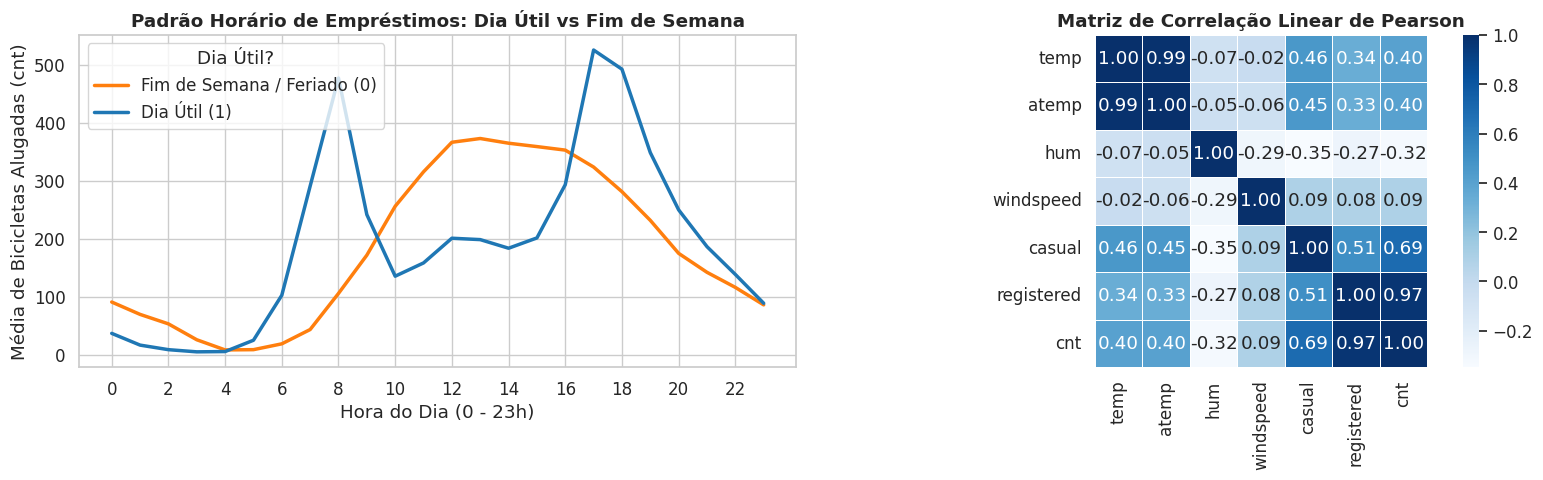

Pico matutino (Dias Úteis - 08h): 477.0 aluguéis/hora
Pico vespertino (Dias Úteis - 17h-18h): 525.3 e 492.2 aluguéis/hora


In [ ]:
# ==============================================================================
# PASSO 3: EVIDÊNCIAS GRÁFICAS DA ANÁLISE EXPLORATÓRIA (EXPLORE / PRODUCE)
# ==============================================================================
import matplotlib.pyplot as plt
import seaborn as sns

# Configurações visuais elegantes para publicação
sns.set_theme(style="whitegrid", font_scale=1.1)
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# 1. Gráfico de Demanda Horária por Tipo de Dia (Útil vs Fim de Semana)
sns.lineplot(
    data=df_raw,
    x='hr',
    y='cnt',
    hue='workingday',
    palette={1: '#1f77b4', 0: '#ff7f0e'},
    ax=axes[0],
    ci=None,
    linewidth=2.5
)
axes[0].set_title("Padrão Horário de Empréstimos: Dia Útil vs Fim de Semana", fontweight='bold')
axes[0].set_xlabel("Hora do Dia (0 - 23h)")
axes[0].set_ylabel("Média de Bicicletas Alugadas (cnt)")
axes[0].legend(title="Dia Útil?", labels=["Fim de Semana / Feriado (0)", "Dia Útil (1)"])
axes[0].set_xticks(range(0, 24, 2))

# 2. Matriz de Correlação das Variáveis Contínuas
cols_corr = ['temp', 'atemp', 'hum', 'windspeed', 'casual', 'registered', 'cnt']
corr = df_raw[cols_corr].corr()

sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    cbar=True,
    ax=axes[1],
    square=True,
    linewidths=0.5
)
axes[1].set_title("Matriz de Correlação Linear de Pearson", fontweight='bold')

plt.tight_layout()
plt.show()

# Resumo numérico do pico de demanda
pico_util = df_raw[df_raw['workingday'] == 1].groupby('hr')['cnt'].mean().round(1)
print(f"Pico matutino (Dias Úteis - 08h): {pico_util[8]} aluguéis/hora")
print(f"Pico vespertino (Dias Úteis - 17h-18h): {pico_util[17]} e {pico_util[18]} aluguéis/hora")

In [ ]:
# Salvar os gráficos em formato PNG de alta resolução para download
fig.savefig("figura1_padrao_horario_demanda.png", dpi=300, bbox_inches='tight')
print("Figura salva com sucesso: figura1_padrao_horario_demanda.png")

# Se quiser baixar direto para o seu computador para inserir no Google Docs:
from google.colab import files
files.download("figura1_padrao_horario_demanda.png")

Figura salva com sucesso: figura1_padrao_horario_demanda.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>